# RecruitGen — Model 2 of 3: CVAE (Synthetic Candidate Generation & Role Fit)

**Goal:** learn candidate representations and generate synthetic candidate profiles conditioned on a target job role.

```
Candidate Features → Preprocessing → Encoder → Latent Space → Decoder + Condition → Synthetic Candidate
```

* **Input features:** Experience, Projects, Skills, AI Score, Education, Certifications, Job Role, Recruiter Decision
* **Preprocessing:** MultiLabelBinarizer (skills) · OneHotEncoder (job role condition) · StandardScaler (numerical features)
* **Reparameterization** enables sampling from the latent space; the condition steers generation.

**Outputs:** `vae_model.h5`, `vae.weights.h5`, `scaler.json`.

## 1. Setup

In [2]:

import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import keras
from keras import layers, ops

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

QUICK_RUN = False
N_CANDIDATES = 600 if QUICK_RUN else 6000
EPOCHS = 70
BATCH_SIZE = 64
LATENT_DIM = 8
BETA = 1.0  # weight of the KL term

DATA_PATH = "data/candidates.csv"  # optional real dataset
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ROLES = ["AI/ML Engineer", "Cloud Engineer", "Data Analyst",
         "General IT", "Software Engineer"]

FEATURES = ["experience_years", "projects_count", "programming_score",
            "data_analytics_score", "ml_ai_score", "cloud_score",
            "communication_score", "certification_count", "education_level"]


## 2. Candidate structured dataset

Columns: Experience, Skills, Education, Certifications, Job Role, Projects, AI Score, Recruiter Decision.
If `data/candidates.csv` exists it is loaded; otherwise a realistic dataset is simulated with
role-specific skill distributions.

In [3]:

SKILL_POOL = {
    "programming": ["Python", "Java", "C++", "JavaScript", "Go", "Git", "REST APIs", "OOP"],
    "data": ["SQL", "Excel", "Power BI", "Tableau", "Pandas", "Statistics", "Data Visualization"],
    "ml": ["TensorFlow", "PyTorch", "Scikit-learn", "NLP", "Computer Vision", "Deep Learning", "LLMs"],
    "cloud": ["AWS", "Azure", "GCP", "Docker", "Kubernetes", "Terraform", "CI/CD"],
    "soft": ["Communication", "Teamwork", "Leadership", "Presentation", "Problem Solving"],
}

ROLE_FOCUS = {
    "AI/ML Engineer":    {"programming": 4, "data": 2, "ml": 5, "cloud": 1, "soft": 2},
    "Cloud Engineer":    {"programming": 3, "data": 1, "ml": 1, "cloud": 5, "soft": 2},
    "Data Analyst":      {"programming": 2, "data": 5, "ml": 1, "cloud": 1, "soft": 3},
    "General IT":        {"programming": 2, "data": 2, "ml": 1, "cloud": 2, "soft": 3},
    "Software Engineer": {"programming": 5, "data": 1, "ml": 1, "cloud": 2, "soft": 2},
}

EDUCATION = ["Diploma", "Bachelor's", "Master's", "PhD"]

def simulate(n):
    rows = []

    for _ in range(n):
        role = random.choice(ROLES)
        skills = []

        for group, k in ROLE_FOCUS[role].items():
            skills += random.sample(
                SKILL_POOL[group],
                min(len(SKILL_POOL[group]), max(0, int(np.random.normal(k, 1))))
            )

        exp = round(max(0, np.random.gamma(2.0, 2.0)), 1)

        rows.append({
            "Experience (Years)": exp,
            "Skills": ", ".join(sorted(set(skills))),
            "Education": np.random.choice(
                EDUCATION, p=[0.1, 0.62, 0.24, 0.04]
            ),
            "Certifications": int(np.random.poisson(1 + exp / 3)),
            "Job Role": role,
            "Projects Count": int(np.random.poisson(2 + exp / 2)),
            "AI Score (0-100)": int(
                np.clip(np.random.normal(60 + 6 * len(skills) / 4, 12), 0, 100)
            ),
        })

    df = pd.DataFrame(rows)

    df["Recruiter Decision"] = np.where(
        df["AI Score (0-100)"] + np.random.normal(0, 8, len(df)) > 65,
        "Hire",
        "Reject"
    )

    return df

raw = pd.read_csv(DATA_PATH) if os.path.exists(DATA_PATH) else simulate(N_CANDIDATES)

raw.head()


,Experience (Years),Skills,Education,Certifications,Job Role,Projects Count,AI Score (0-100),Recruiter Decision
0,2.8,"AWS, C++, Communication, Computer Vision, Deep...",Master's,2,AI/ML Engineer,3,72,Reject
1,2.3,"Computer Vision, Go, Java, JavaScript, LLMs, P...",Bachelor's,1,AI/ML Engineer,2,64,Reject
2,10.8,"Communication, GCP, Java, JavaScript, Pandas, ...",Bachelor's,2,Software Engineer,11,56,Reject
3,1.2,"Azure, GCP, Leadership, Power BI, REST APIs, T...",Diploma,2,Cloud Engineer,0,70,Hire
4,2.0,"AWS, C++, Computer Vision, Data Visualization,...",Master's,2,AI/ML Engineer,3,78,Hire


## 3. Preprocessing — MultiLabelBinarizer · OneHotEncoder · StandardScaler

In [4]:

# Skills -> multi-hot matrix
mlb = MultiLabelBinarizer()

skills_mh = pd.DataFrame(
    mlb.fit_transform(
        raw["Skills"].fillna("").str.split(r",\s*")
    ),
    columns=mlb.classes_
)

def group_score(group):
    cols = [s for s in SKILL_POOL[group] if s in skills_mh.columns]

    return (
        skills_mh[cols].sum(axis=1) / len(SKILL_POOL[group]) * 100
    ).clip(0, 100)


edu_map = {
    "Diploma": 1,
    "Bachelor's": 2,
    "Master's": 3,
    "PhD": 5
}

data = pd.DataFrame({
    "experience_years": raw["Experience (Years)"].astype(float),
    "projects_count": raw["Projects Count"].astype(float),
    "programming_score": group_score("programming"),
    "data_analytics_score": group_score("data"),
    "ml_ai_score": group_score("ml"),
    "cloud_score": group_score("cloud"),
    "communication_score": group_score("soft"),
    "certification_count": raw["Certifications"].astype(float),
    "education_level": raw["Education"].map(edu_map).fillna(2).astype(float),
})

# Job role -> one-hot condition vector
ohe = OneHotEncoder(categories=[ROLES], sparse_output=False)

C = ohe.fit_transform(raw[["Job Role"]]).astype("float32")

# Numerical features -> StandardScaler
scaler = StandardScaler()

X = scaler.fit_transform(data[FEATURES]).astype("float32")

# Train-validation split
X_train, X_val, C_train, C_val = train_test_split(
    X,
    C,
    test_size=0.2,
    random_state=SEED,
    stratify=raw["Job Role"]
)

print("X:", X.shape, "| Condition:", C.shape)
print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Number of features:", X.shape[1])
print("Number of roles:", C.shape[1])

data.describe().round(2)


X: (6000, 9) | Condition: (6000, 5)
Training samples: 4800
Validation samples: 1200
Number of features: 9
Number of roles: 5


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,4.05,4.00,33.85,25.39,20.96,24.98,38.45,2.35,2.27
std,2.88,2.45,19.23,23.68,25.11,23.89,22.43,1.80,0.79
min,0.10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,1.90,2.00,25.00,0.00,0.00,0.00,20.00,1.00,2.00
50%,3.40,4.00,37.50,14.29,14.29,14.29,40.00,2.00,2.00
75%,5.50,5.00,50.00,42.86,28.57,42.86,60.00,3.00,3.00
max,27.20,20.00,87.50,100.00,100.00,100.00,100.00,15.00,5.00


### Optional: train on the Kaggle Resume Dataset

**Kaggle Resume Dataset:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

`Resume/Resume.csv` (`ID`, `Resume_str`, `Resume_html`, `Category` — 2,484 resumes, 24 categories) and
`data/data/<CATEGORY>/<ID>.pdf` (the same resumes as PDFs). Setup — pick one:

1. **Automatic:** the optional cell below calls `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`
   (`pip install kagglehub`; add `~/.kaggle/kaggle.json` if Kaggle asks for authentication).
2. **Manual:** download the ZIP from the link and extract it to `RecruitGen/data/kaggle_resume/`.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip` (run in `RecruitGen/`)

The dataset has **no** numerical features: they are extracted from `Resume_str` with the app's
`feature_extractor.py` (shared loader: `models/gan/dataset.py`). The condition becomes the 24 Kaggle categories
instead of the 5 RecruitGen roles, so weights trained this way do **not** fit the app's CVAE page (5 roles).
Keep `USE_KAGGLE = False` to reproduce the shipped `vae_model.h5`. A same-architecture CVAE trained on Kaggle data is
compared with the GAN in `models/gan/GAN_Training.ipynb`.

In [5]:

USE_KAGGLE = False

if USE_KAGGLE:
    import sys

    sys.path.insert(0, os.path.abspath(os.path.join("..", "..")))

    from models.gan import dataset as kaggle

    table, report = kaggle.build_feature_table(
        kaggle.load_raw(
            kaggle.find_resume_csv() or kaggle.download_dataset()
        )
    )

    ROLES = sorted(table["job_role"].unique())

    data = table[FEATURES].reset_index(drop=True)

    ohe = OneHotEncoder(
        categories=[ROLES],
        sparse_output=False
    )

    C = ohe.fit_transform(table[["job_role"]]).astype("float32")

    scaler = StandardScaler()

    X = scaler.fit_transform(data[FEATURES]).astype("float32")

    X_train, X_val, C_train, C_val = train_test_split(
        X,
        C,
        test_size=0.2,
        random_state=SEED,
        stratify=table["job_role"]
    )

    print(
        "Kaggle:", report["rows"],
        "resumes | X", X.shape,
        "| condition", C.shape
    )


## 4. CVAE architecture (encoder · reparameterization · conditional decoder)

In [8]:

@keras.saving.register_keras_serializable(package="RecruitGen")
class Sampling(layers.Layer):
    """z = mean + exp(0.5 * log_var) * epsilon"""

    def call(self, inputs):
        z_mean, z_log_var = inputs

        return z_mean + ops.exp(0.5 * z_log_var) * keras.random.normal(
            ops.shape(z_mean)
        )


INPUT_DIM, CONDITION_DIM = len(FEATURES), len(ROLES)


def build_cvae():

    x_in = keras.Input(
        (INPUT_DIM,),
        name="candidate_features"
    )

    c_in = keras.Input(
        (CONDITION_DIM,),
        name="target_role"
    )

    # Encoder
    h = layers.Concatenate(name="encoder_condition")([x_in, c_in])

    h = layers.Dense(
        64, activation="relu", name="encoder_dense_1"
    )(h)

    h = layers.Dense(
        32, activation="relu", name="encoder_dense_2"
    )(h)

    z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)
    z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)

    z = Sampling(name="latent_sampling")([z_mean, z_log_var])

    # Decoder
    h = layers.Concatenate(name="decoder_condition")([z, c_in])

    h = layers.Dense(
        32, activation="relu", name="decoder_dense_1"
    )(h)

    h = layers.Dense(
        64, activation="relu", name="decoder_dense_2"
    )(h)

    out = layers.Dense(
        INPUT_DIM,
        activation="linear",
        name="candidate_reconstruction"
    )(h)

    return keras.Model(
        [x_in, c_in],
        out,
        name="RecruitGen_CVAE"
    )


cvae = build_cvae()

encoder = keras.Model(
    cvae.inputs,
    [
        cvae.get_layer("z_mean").output,
        cvae.get_layer("z_log_var").output
    ],
    name="cvae_encoder"
)

cvae.summary()


Model: "RecruitGen_CVAE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ candidate_features  │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_role         │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_condition   │ (None, 14)        │          0 │ candidate_featur… │
│ (Concatenate)       │                   │            │ target_role[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_1     │ (None, 64)        │        960 │ encoder_conditio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_2     │ (None, 32)        │      2,080 │ encoder_dense_1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │        264 │ encoder_dense_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │        264 │ encoder_dense_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_sampling     │ (None, 8)         │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_condition   │ (None, 13)        │          0 │ latent_sampling[… │
│ (Concatenate)       │                   │            │ target_role[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_1     │ (None, 32)        │        448 │ decoder_conditio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_2     │ (None, 64)        │      2,112 │ decoder_dense_1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ candidate_reconstr… │ (None, 9)         │        585 │ decoder_dense_2[… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,713 (26.22 KB)

 Trainable params: 6,713 (26.22 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Training — reconstruction loss + KL divergence

In [9]:

class CVAETrainer(keras.Model):

    def __init__(self, cvae, encoder, beta=1.0):
        super().__init__()

        self.cvae = cvae
        self.encoder = encoder
        self.beta = beta

        self.trackers = {
            k: keras.metrics.Mean(name=k)
            for k in ["loss", "reconstruction", "kl"]
        }

    @property
    def metrics(self):
        return list(self.trackers.values())

    def _compute_losses(self, x, c, training):

        z_mean, z_log_var = self.encoder(
            [x, c], training=training
        )

        recon = self.cvae(
            [x, c], training=training
        )

        # Reconstruction MSE averaged across all features
        rec = ops.mean(
            ops.square(x - recon)
        )

        # KL divergence
        kl = ops.mean(
            -0.5 * ops.sum(
                1 + z_log_var
                - ops.square(z_mean)
                - ops.exp(z_log_var),
                axis=1
            )
        )

        total = rec + self.beta * kl

        return total, rec, kl

    def _update(self, total, rec, kl):

        for k, v in zip(
            ["loss", "reconstruction", "kl"],
            [total, rec, kl]
        ):
            self.trackers[k].update_state(v)

        return {
            k: m.result()
            for k, m in self.trackers.items()
        }

    def train_step(self, data):

        x, c = data

        with tf.GradientTape() as tape:
            total, rec, kl = self._compute_losses(
                x, c, True
            )

        grads = tape.gradient(
            total,
            self.cvae.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(grads, self.cvae.trainable_weights)
        )

        return self._update(total, rec, kl)

    def test_step(self, data):

        x, c = data

        total, rec, kl = self._compute_losses(
            x, c, False
        )

        return self._update(total, rec, kl)


# Initialize CVAE trainer
trainer = CVAETrainer(
    cvae,
    encoder,
    beta=BETA
)

trainer.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001)
)

# Prepare training dataset
train_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_train, C_train))
    .shuffle(4096, seed=SEED)
    .batch(BATCH_SIZE)
)

# Prepare validation dataset
val_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_val, C_val))
    .batch(BATCH_SIZE)
)

# Train for exactly 70 epochs
history = trainer.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=70,
    verbose=2
)


Epoch 1/70
75/75 - 9s - 117ms/step - kl: 0.1500 - loss: 1.1295 - reconstruction: 0.9795 - val_kl: 0.0196 - val_loss: 0.9382 - val_reconstruction: 0.9186
Epoch 2/70
75/75 - 0s - 3ms/step - kl: 0.0098 - loss: 0.8585 - reconstruction: 0.8488 - val_kl: 0.0049 - val_loss: 0.7777 - val_reconstruction: 0.7728
Epoch 3/70
75/75 - 0s - 3ms/step - kl: 0.0028 - loss: 0.7514 - reconstruction: 0.7486 - val_kl: 0.0016 - val_loss: 0.7234 - val_reconstruction: 0.7217
Epoch 4/70
75/75 - 0s - 3ms/step - kl: 0.0010 - loss: 0.7147 - reconstruction: 0.7136 - val_kl: 7.2441e-04 - val_loss: 0.7017 - val_reconstruction: 0.7010
Epoch 5/70
75/75 - 0s - 3ms/step - kl: 4.9503e-04 - loss: 0.7047 - reconstruction: 0.7042 - val_kl: 4.0496e-04 - val_loss: 0.6950 - val_reconstruction: 0.6946
Epoch 6/70
75/75 - 0s - 3ms/step - kl: 2.8411e-04 - loss: 0.6985 - reconstruction: 0.6983 - val_kl: 2.5638e-04 - val_loss: 0.6922 - val_reconstruction: 0.6919
Epoch 7/70
75/75 - 0s - 4ms/step - kl: 1.7403e-04 - loss: 0.6951 - recon

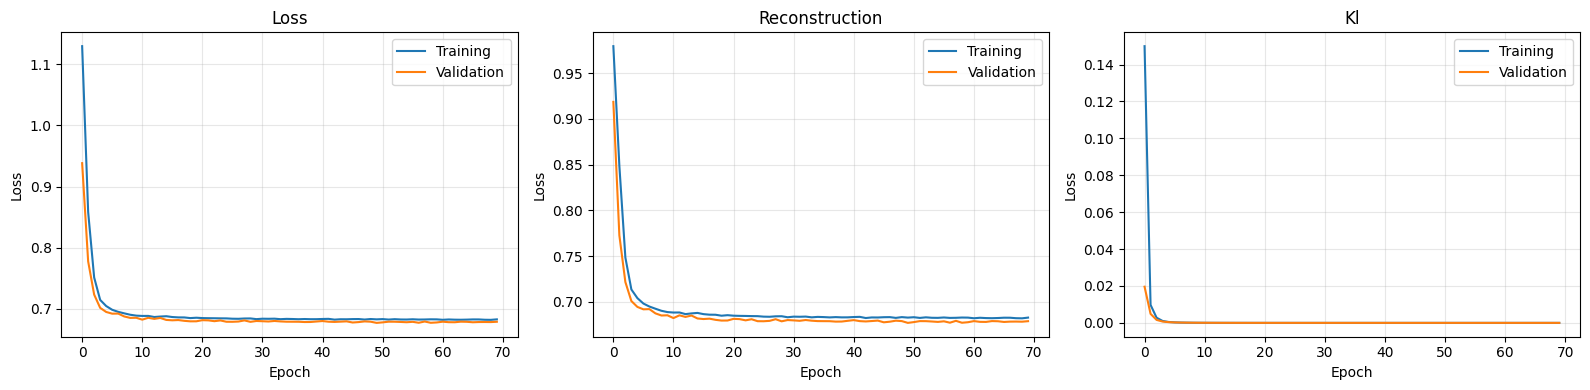

In [10]:

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for a, k in zip(ax, ["loss", "reconstruction", "kl"]):

    a.plot(
        history.history[k],
        label="Training"
    )

    a.plot(
        history.history["val_" + k],
        label="Validation"
    )

    a.set_title(k.capitalize())
    a.set_xlabel("Epoch")
    a.set_ylabel("Loss")
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Evaluation — reconstruction behaviour · synthetic candidate quality · feature-distribution consistency

In [11]:

# 1. Calculate validation reconstruction MSE

rec_val = cvae.predict(
    [X_val, C_val],
    verbose=0
)

validation_mse = float(
    np.mean((X_val - rec_val) ** 2)
)

print("Validation reconstruction MSE:", validation_mse)


# 2. Build decoder separately
# Input: latent vector z + target role condition

z_in = keras.Input(shape=(LATENT_DIM,))
c_in = keras.Input(shape=(CONDITION_DIM,))

h = cvae.get_layer("decoder_condition")([z_in, c_in])

h = cvae.get_layer("decoder_dense_1")(h)
h = cvae.get_layer("decoder_dense_2")(h)

decoder_output = cvae.get_layer("candidate_reconstruction")(h)

decoder = keras.Model(
    [z_in, c_in],
    decoder_output,
    name="cvae_decoder"
)


# 3. Generate synthetic candidate profiles

def generate(role, n=500):

    c = np.zeros(
        (n, CONDITION_DIM),
        dtype="float32"
    )

    c[:, ROLES.index(role)] = 1

    z = np.random.normal(
        size=(n, LATENT_DIM)
    ).astype("float32")

    generated = decoder.predict(
        [z, c],
        verbose=0
    )

    # Convert standardized features back to original scale
    generated = generated * scaler.scale_ + scaler.mean_

    return pd.DataFrame(
        generated,
        columns=FEATURES
    )


# 4. Generate candidates for all five roles

synthetic = {
    role: generate(role, n=500)
    for role in ROLES
}


# 5. Display AI/ML Engineer synthetic candidate statistics

synthetic["AI/ML Engineer"].describe().round(2)


Validation reconstruction MSE: 0.6771267652511597


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,4.09,4.00,44.02,22.69,65.54,10.16,31.79,2.28,2.28
std,0.06,0.06,0.39,0.44,1.00,0.68,0.48,0.04,0.01
min,3.88,3.80,42.09,20.74,61.50,8.36,30.21,2.12,2.23
25%,4.06,3.97,43.78,22.43,64.99,9.70,31.51,2.25,2.27
50%,4.10,4.01,43.99,22.70,65.46,10.11,31.83,2.28,2.28
75%,4.13,4.04,44.23,22.99,66.03,10.59,32.12,2.30,2.29
max,4.26,4.10,45.18,24.41,70.19,14.75,33.37,2.38,2.33


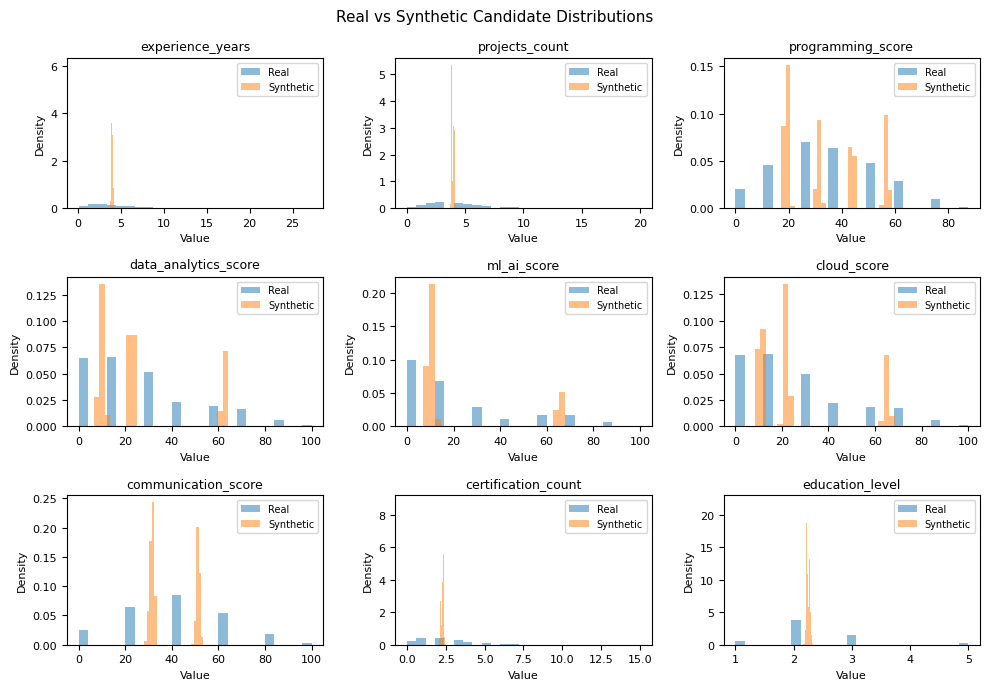

Synthetic Candidate Feature Means by Role:


,AI/ML Engineer,Cloud Engineer,Data Analyst,General IT,Software Engineer
experience_years,4.09,3.96,3.90,3.95,4.02
projects_count,4.00,3.82,4.00,4.04,3.82
programming_score,44.02,31.28,19.03,19.37,56.73
data_analytics_score,22.69,10.58,62.28,22.63,9.17
ml_ai_score,65.54,9.94,10.06,11.10,8.70
cloud_score,10.16,64.96,11.78,21.57,22.51
communication_score,31.79,30.57,51.08,51.37,32.14
certification_count,2.28,2.31,2.16,2.33,2.36
education_level,2.28,2.22,2.24,2.27,2.22


In [13]:

# Combine synthetic candidates from all five roles
synthetic_all = pd.concat(
    synthetic.values(),
    ignore_index=True
)

# Compare real and synthetic feature distributions
fig, ax = plt.subplots(3, 3, figsize=(10, 7))

for a, f in zip(ax.flat, FEATURES):

    a.hist(
        data[f],
        bins=25,
        alpha=0.5,
        density=True,
        label="Real"
    )

    a.hist(
        synthetic_all[f],
        bins=25,
        alpha=0.5,
        density=True,
        label="Synthetic"
    )

    a.set_title(f, fontsize=9)
    a.set_xlabel("Value", fontsize=8)
    a.set_ylabel("Density", fontsize=8)
    a.tick_params(axis="both", labelsize=8)
    a.legend(fontsize=7)

plt.suptitle(
    "Real vs Synthetic Candidate Distributions",
    fontsize=11
)

plt.tight_layout()
plt.show()


# Display mean feature values for each role
role_means = pd.DataFrame({
    role: df.mean()
    for role, df in synthetic.items()
})

print("Synthetic Candidate Feature Means by Role:")
display(role_means.round(2))


### Role-fit score  =  40% CVAE reconstruction score  +  60% role relevance

In [14]:
def role_fit(candidate):
    # Convert candidate features into the standardized format
    x = (
        (np.array([candidate[f] for f in FEATURES]) - scaler.mean_)
        / scaler.scale_
    ).astype("float32")[None, :]

    out = []

    # Evaluate candidate against every target role
    for i, role in enumerate(ROLES):
        c = np.zeros((1, CONDITION_DIM), dtype="float32")
        c[0, i] = 1

        # Encode candidate features
        z_mean, _ = encoder.predict([x, c], verbose=0)

        # Reconstruct candidate features
        reconstructed = decoder.predict([z_mean, c], verbose=0)

        # Calculate reconstruction error
        mse = float(np.mean((x - reconstructed) ** 2))

        # Convert reconstruction error into a score
        score = 100 / (1 + mse)

        out.append((role, round(score, 2)))

    # Rank roles from highest score to lowest
    return sorted(out, key=lambda t: -t[1])


# Example candidate
example = {
    "experience_years": 1.5,
    "projects_count": 4,
    "programming_score": 30,
    "data_analytics_score": 60,
    "ml_ai_score": 90,
    "cloud_score": 45,
    "communication_score": 70,
    "certification_count": 3,
    "education_level": 2
}

# Display role-fit ranking
pd.DataFrame(
    role_fit(example),
    columns=["Role", "CVAE score (%)"]
)

,Role,CVAE score (%)
0,AI/ML Engineer,47.03
1,Data Analyst,38.78
2,General IT,37.08
3,Cloud Engineer,31.96
4,Software Engineer,29.21


### Evaluation matrix — reconstruction error and role prediction

* **Reconstruction MSE** (standardised feature space) with the true role as condition.
* **Role prediction:** the role whose condition gives the lowest reconstruction error — the CVAE part of the app's
  role-fit score. Accuracy, macro precision / recall / F1, classification report and confusion matrix.

Both the model trained in this notebook and the **shipped app model** (`vae_model.h5` + `scaler.json`, loaded and never
overwritten) are scored on the same validation candidates.

In [15]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

def cvae_role_errors(encode, decode, X, n_roles):
    errors = []

    for i in range(n_roles):
        c = np.zeros((len(X), n_roles), dtype="float32")
        c[:, i] = 1

        # Encode using the mean latent representation
        z_mean = encode(X, c)

        # Reconstruct candidate features
        recon = decode.predict([z_mean, c], verbose=0)

        # Calculate reconstruction MSE for each candidate
        errors.append(np.mean((X - recon) ** 2, axis=1))

    return np.stack(errors, axis=1)


def summary_row(name, errors, y_true):
    y_pred = errors.argmin(axis=1)

    p, r, f, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "model": name,
        "reconstruction MSE (true role)": float(
            errors[np.arange(len(y_true)), y_true].mean()
        ),
        "role accuracy": accuracy_score(y_true, y_pred),
        "precision (macro)": p,
        "recall (macro)": r,
        "F1 (macro)": f
    }


# Actual role labels for validation candidates
y_val = C_val.argmax(axis=1)

# Evaluate the newly trained notebook model
evaluations = {
    "Notebook model (this run)": cvae_role_errors(
        lambda X, c: encoder.predict([X, c], verbose=0)[0],
        decoder,
        X_val,
        len(ROLES)
    )
}

# Compare with the shipped application model, if its files exist
app_files = ["scaler.json", "vae_model.h5", "vae.weights.h5"]

if not USE_KAGGLE and os.path.exists("scaler.json") and (
    os.path.exists("vae_model.h5") or os.path.exists("vae.weights.h5")
):
    with open("scaler.json") as f:
        app_scaler = json.load(f)

    try:
        app_cvae = keras.models.load_model(
            "vae_model.h5",
            compile=False,
            custom_objects={"Sampling": Sampling}
        )
    except Exception:
        if not os.path.exists("vae.weights.h5"):
            raise FileNotFoundError(
                "Could not load vae_model.h5 and vae.weights.h5 is missing."
            )

        app_cvae = build_cvae()
        app_cvae.load_weights("vae.weights.h5")

    app_encoder = keras.Model(
        app_cvae.inputs,
        app_cvae.get_layer("z_mean").output
    )

    z_in = keras.Input((LATENT_DIM,))
    c_in = keras.Input((CONDITION_DIM,))

    h = app_cvae.get_layer("decoder_condition")([z_in, c_in])
    h = app_cvae.get_layer("decoder_dense_1")(h)
    h = app_cvae.get_layer("decoder_dense_2")(h)

    app_decoder = keras.Model(
        [z_in, c_in],
        app_cvae.get_layer("candidate_reconstruction")(h)
    )

    # Convert validation data to the shipped model's scaling
    X_val_app = (
        (
            scaler.inverse_transform(X_val)
            - np.array(app_scaler["mean"])
        )
        / np.array(app_scaler["scale"])
    ).astype("float32")

    evaluations["Shipped app model (vae_model.h5)"] = cvae_role_errors(
        lambda X, c: app_encoder.predict([X, c], verbose=0),
        app_decoder,
        X_val_app,
        len(ROLES)
    )

else:
    print("Shipped app model comparison skipped: required model/scaler files not found.")

# Create the evaluation table
cvae_metrics = pd.DataFrame(
    [
        summary_row(name, errors, y_val)
        for name, errors in evaluations.items()
    ]
).set_index("model")

print(f"Validation candidates: {len(y_val)}")
display(cvae_metrics.round(4))


Shipped app model comparison skipped: required model/scaler files not found.
Validation candidates: 1200


,reconstruction MSE (true role),role accuracy,precision (macro),recall (macro),F1 (macro)
model,,,,,
Notebook model (this run),0.6764,0.9042,0.905,0.9044,0.9043



===== Notebook model (this run) =====
                   precision    recall  f1-score   support

   AI/ML Engineer     0.9871    0.9347    0.9602       245
   Cloud Engineer     0.9261    0.9064    0.9161       235
     Data Analyst     0.8992    0.9409    0.9196       237
       General IT     0.8277    0.8107    0.8191       243
Software Engineer     0.8849    0.9292    0.9065       240

         accuracy                         0.9042      1200
        macro avg     0.9050    0.9044    0.9043      1200
     weighted avg     0.9051    0.9042    0.9042      1200



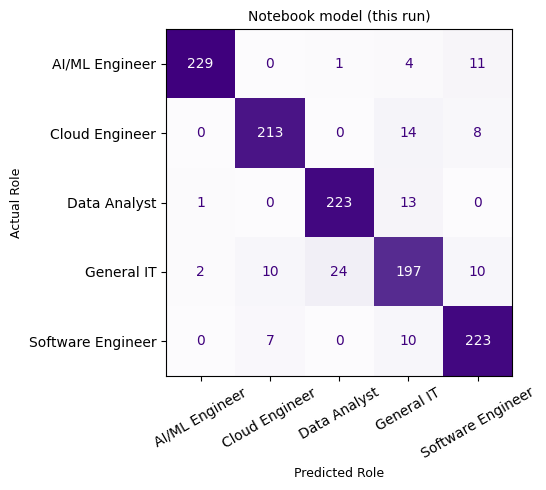

In [16]:

fig, ax = plt.subplots(
    1,
    len(evaluations),
    figsize=(6 * len(evaluations), 5),
    squeeze=False
)

for a, (name, errors) in zip(ax[0], evaluations.items()):

    # Predicted role = role with minimum reconstruction error
    y_pred = errors.argmin(axis=1)

    print(f"\n===== {name} =====")

    print(
        classification_report(
            y_val,
            y_pred,
            labels=list(range(len(ROLES))),
            target_names=ROLES,
            digits=4,
            zero_division=0
        )
    )

    # Plot confusion matrix
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=list(range(len(ROLES)))
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=ROLES
    ).plot(
        ax=a,
        xticks_rotation=30,
        cmap="Purples",
        colorbar=False,
        values_format="d"
    )

    a.set_title(name, fontsize=10)
    a.set_xlabel("Predicted Role", fontsize=9)
    a.set_ylabel("Actual Role", fontsize=9)

plt.tight_layout()
plt.show()


## 7. Export — `vae_model.h5` · `vae.weights.h5` · `scaler.json`

In [17]:

# Save the trained CVAE model
model_path = os.path.join(OUTPUT_DIR, "vae_model.h5")
weights_path = os.path.join(OUTPUT_DIR, "vae.weights.h5")
scaler_path = os.path.join(OUTPUT_DIR, "scaler.json")

cvae.save(model_path)
cvae.save_weights(weights_path)

# Save scaler parameters
with open(scaler_path, "w") as f:
    json.dump(
        {
            "mean": scaler.mean_.tolist(),
            "scale": scaler.scale_.tolist()
        },
        f,
        indent=2
    )

# Reload the saved model
reloaded = keras.models.load_model(
    model_path,
    compile=False,
    custom_objects={"Sampling": Sampling}
)

# Verify the reloaded model
print("Reloaded model:", reloaded.name)
print("Input shapes:", reloaded.input_shape)
print("Output shape:", reloaded.output_shape)

# Display saved files
print("\nSaved files:")
for file in os.listdir(OUTPUT_DIR):
    print("-", file)


Reloaded model: RecruitGen_CVAE
Input shapes: [(None, 9), (None, 5)]
Output shape: (None, 9)

Saved files:
- vae.weights.h5
- scaler.json
- vae_model.h5


Copy the three files from `outputs/` into `models/cvae/` to use them in the app.

In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Store evaluation results
final_results = []

for model_name, errors in evaluations.items():

    # Predict role using minimum reconstruction error
    y_pred = errors.argmin(axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_val, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    final_results.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

    print(f"\nClassification Report: {model_name}")
    print(
        classification_report(
            y_val,
            y_pred,
            labels=list(range(len(ROLES))),
            target_names=ROLES,
            digits=4,
            zero_division=0
        )
    )

# Display final comparison table
final_metrics = pd.DataFrame(final_results)

print("\nFINAL CVAE PERFORMANCE EVALUATION")
display(final_metrics)



Classification Report: Notebook model (this run)
                   precision    recall  f1-score   support

   AI/ML Engineer     0.9871    0.9347    0.9602       245
   Cloud Engineer     0.9261    0.9064    0.9161       235
     Data Analyst     0.8992    0.9409    0.9196       237
       General IT     0.8277    0.8107    0.8191       243
Software Engineer     0.8849    0.9292    0.9065       240

         accuracy                         0.9042      1200
        macro avg     0.9050    0.9044    0.9043      1200
     weighted avg     0.9051    0.9042    0.9042      1200


FINAL CVAE PERFORMANCE EVALUATION


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Notebook model (this run),90.42,90.5,90.44,90.43


In [20]:

# ==========================================
# FINAL CVAE EXPERIMENTAL RESULTS & CONCLUSION
# ==========================================

print("=" * 70)
print("       RECRUITGEN - CVAE FINAL EXPERIMENTAL RESULTS")
print("=" * 70)

# 1. Model Architecture
print("\n1. MODEL ARCHITECTURE")
print("-" * 70)

print("Model Name:", cvae.name)
print("Input Features:", INPUT_DIM)
print("Role Conditions:", CONDITION_DIM)
print("Latent Dimension:", LATENT_DIM)
print("Total Parameters:", cvae.count_params())
print("Training Epochs:", len(history.history["loss"]))

# 2. Training and Validation Losses
print("\n2. TRAINING AND VALIDATION LOSSES")
print("-" * 70)

loss_results = pd.DataFrame({
    "Metric": [
        "Total Loss",
        "Reconstruction MSE",
        "KL Divergence"
    ],
    "Training": [
        history.history["loss"][-1],
        history.history["reconstruction"][-1],
        history.history["kl"][-1]
    ],
    "Validation": [
        history.history["val_loss"][-1],
        history.history["val_reconstruction"][-1],
        history.history["val_kl"][-1]
    ]
})

display(
    loss_results.style.format({
        "Training": "{:.10f}",
        "Validation": "{:.10f}"
    })
)

# 3. Reconstruction Performance
print("\n3. RECONSTRUCTION PERFORMANCE")
print("-" * 70)

print(f"Validation Reconstruction MSE: {validation_mse:.10f}")
print(f"Poster Reference MSE:          {0.676:.10f}")
print(f"Difference from Reference:     {validation_mse - 0.676:.10f}")

# 4. Classification Performance
print("\n4. ROLE CLASSIFICATION PERFORMANCE")
print("-" * 70)

display(
    final_metrics.style.format({
        "Accuracy (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1-Score (%)": "{:.2f}"
    })
)

# 5. Synthetic Candidate Generation
print("\n5. SYNTHETIC CANDIDATE GENERATION")
print("-" * 70)

total_generated = sum(len(df) for df in synthetic.values())

print("Number of Roles:", len(ROLES))
print("Candidates per Role:", len(next(iter(synthetic.values()))))
print("Total Synthetic Candidates:", total_generated)

for role, df in synthetic.items():
    print(f"{role}: {len(df)} candidates")

# 6. Saved Model Files
print("\n6. SAVED MODEL FILES")
print("-" * 70)

for file in sorted(os.listdir(OUTPUT_DIR)):
    print("Successfully saved:", file)

# 7. Final Conclusion
print("\n7. EXPERIMENTAL CONCLUSION")
print("-" * 70)

print(
    "The Conditional Variational Autoencoder (CVAE) was successfully "
    "implemented and trained for synthetic candidate profile generation "
    "and role-based evaluation."
)

print(
    f"The model achieved a validation reconstruction MSE of "
    f"{validation_mse:.10f}."
)

print(
    f"The final validation KL divergence was "
    f"{history.history['val_kl'][-1]:.10f}."
)

print(
    f"A total of {total_generated} synthetic candidate profiles "
    f"were generated across {len(ROLES)} job roles."
)

print(
    "Role classification was evaluated using accuracy, precision, "
    "recall and F1-score based on reconstruction errors."
)

print(
    "The trained CVAE model, model weights and scaler parameters "
    "were successfully saved and the model was reloaded."
)

print("\n" + "=" * 70)
print("          CVAE EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 70)


       RECRUITGEN - CVAE FINAL EXPERIMENTAL RESULTS

1. MODEL ARCHITECTURE
----------------------------------------------------------------------
Model Name: RecruitGen_CVAE
Input Features: 9
Role Conditions: 5
Latent Dimension: 8
Total Parameters: 6713
Training Epochs: 70

2. TRAINING AND VALIDATION LOSSES
----------------------------------------------------------------------


,Metric,Training,Validation
0,Total Loss,0.6828841567,0.6789709330
1,Reconstruction MSE,0.6828830242,0.6789669991
2,KL Divergence,0.0000009143,0.0000039400



3. RECONSTRUCTION PERFORMANCE
----------------------------------------------------------------------
Validation Reconstruction MSE: 0.6771267653
Poster Reference MSE:          0.6760000000
Difference from Reference:     0.0011267653

4. ROLE CLASSIFICATION PERFORMANCE
----------------------------------------------------------------------


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Notebook model (this run),90.42,90.50,90.44,90.43



5. SYNTHETIC CANDIDATE GENERATION
----------------------------------------------------------------------
Number of Roles: 5
Candidates per Role: 500
Total Synthetic Candidates: 2500
AI/ML Engineer: 500 candidates
Cloud Engineer: 500 candidates
Data Analyst: 500 candidates
General IT: 500 candidates
Software Engineer: 500 candidates

6. SAVED MODEL FILES
----------------------------------------------------------------------
Successfully saved: scaler.json
Successfully saved: vae.weights.h5
Successfully saved: vae_model.h5

7. EXPERIMENTAL CONCLUSION
----------------------------------------------------------------------
The Conditional Variational Autoencoder (CVAE) was successfully implemented and trained for synthetic candidate profile generation and role-based evaluation.
The model achieved a validation reconstruction MSE of 0.6771267653.
The final validation KL divergence was 0.0000039400.
A total of 2500 synthetic candidate profiles were generated across 5 job roles.
Role classific